# Supplementary Figure S7f. Biomarker-QTL recall and enrichment of cell-type-resolved *trans*-eQTL

For each snRNA-seq cell type, *trans*-eQTL loci (*trans*-eGene and *trans*-eProgram combined) are compared with protein-, metabolite- and glycoprotein-QTL loci. Recall = loci shared with the biomarker-QTL / all biomarker-QTL loci; enrichment = (shared / cell-type *trans* loci) / (shared / all *trans* loci in the global baseline, 118,897 loci). Error bars are 95% CIs, estimate ± 1.96 × leave-one-chromosome-out jackknife SE (22 chromosomes). The dashed line marks enrichment = 1. Values were taken from the author's `recall_enrichment_source.tsv` (the upstream script that wrote it was not located); recall, enrichment and the CI bounds were checked against the counts and SEs stored in the same file.

Input: `data/Figure_S7f_celltype_recall_enrichment.rds`.

In [1]:
library(ggplot2)
s7f <- readRDS("data/Figure_S7f_celltype_recall_enrichment.rds")
s7f[, c("biomarker", "cell_type", "n_celltype_loci", "n_overlap", "recall", "recall_ci_low", "recall_ci_high",
        "enrichment", "enrichment_ci_low", "enrichment_ci_high")]

biomarker,cell_type,n_celltype_loci,n_overlap,recall,recall_ci_low,recall_ci_high,enrichment,enrichment_ci_low,enrichment_ci_high
<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Protein QTL,Excitatory neuron,12660,336,0.02822818,0.02489659,0.03155977,1.0773507,0.9457848,1.208917
Protein QTL,Inhibitory neuron,17923,575,0.04830715,0.04357295,0.05304135,1.3022929,1.1601861,1.444400
Protein QTL,Microglia,16534,501,0.04209023,0.03861828,0.04556218,1.2300176,1.0489760,1.411059
Protein QTL,Astrocyte,20880,649,0.05452407,0.05035544,0.05869270,1.2617280,1.1242317,1.399224
Protein QTL,Oligodendrocyte,21091,674,0.05662438,0.05191036,0.06133841,1.2972218,1.1561985,1.438245
Protein QTL,OPC,19896,692,0.05813660,0.05342332,0.06284989,1.4118607,1.2632067,1.560515
Metabolite QTL,Excitatory neuron,12660,28,0.01985816,0.01324375,0.02647256,0.8243365,0.4997627,1.148910
Metabolite QTL,Inhibitory neuron,17923,53,0.03758865,0.02708841,0.04808890,1.1021619,0.7764255,1.427898
Metabolite QTL,Microglia,16534,55,0.03900709,0.02987756,0.04813662,1.2398381,0.9413837,1.538292


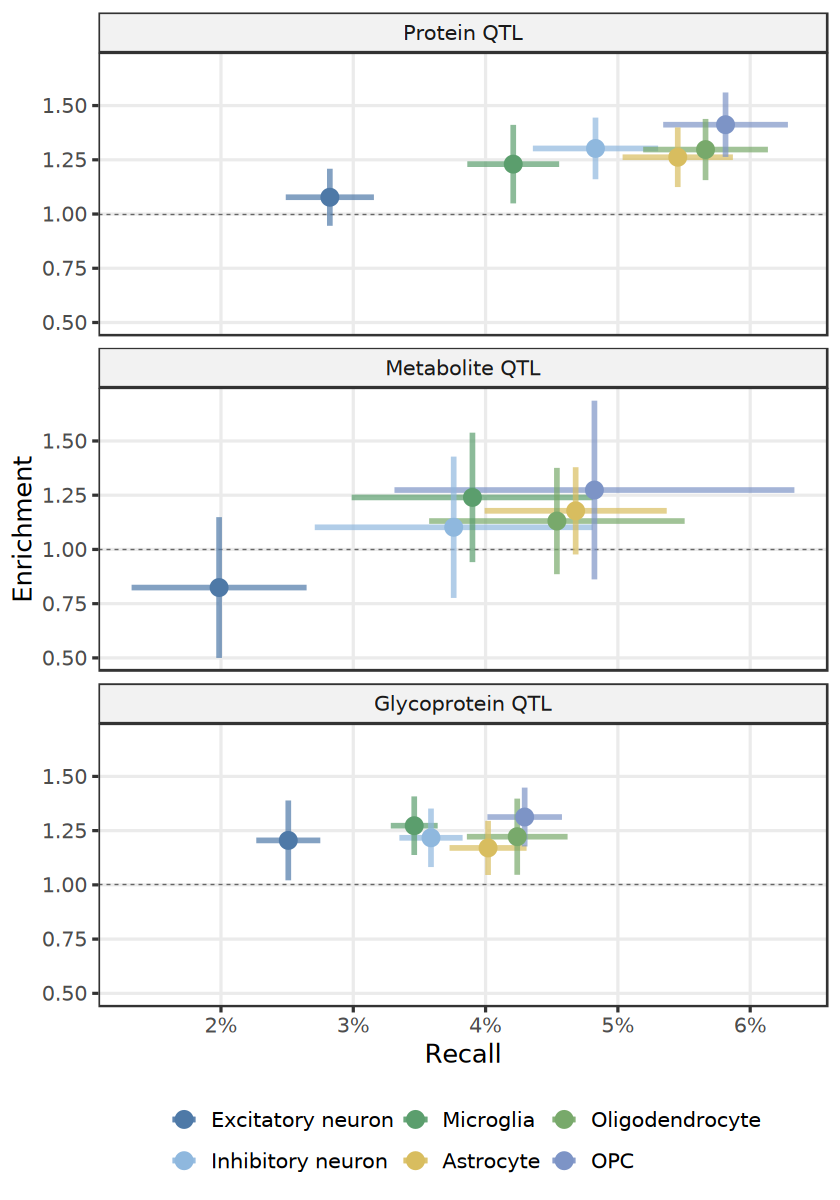

In [2]:
ct_levels <- c("Excitatory neuron", "Inhibitory neuron", "Microglia", "Astrocyte", "Oligodendrocyte", "OPC")
ct_colors <- c("Excitatory neuron" = "#4E79A7", "Inhibitory neuron" = "#8FB8DE", "Microglia" = "#5B9E6D",
               "Astrocyte" = "#D8BD5F", "Oligodendrocyte" = "#78A96B", "OPC" = "#7D94C6")
s7f$cell_type <- factor(s7f$cell_type, levels = ct_levels)
s7f$biomarker <- factor(s7f$biomarker, levels = c("Protein QTL", "Metabolite QTL", "Glycoprotein QTL"))

p <- ggplot(s7f, aes(x = recall, y = enrichment, color = cell_type)) +
  geom_hline(yintercept = 1, linetype = "dashed", linewidth = 0.3, color = "grey40") +
  geom_errorbar(aes(xmin = recall_ci_low, xmax = recall_ci_high), width = 0, orientation = "y",
                linewidth = 1.2, alpha = 0.7) +
  geom_errorbar(aes(ymin = enrichment_ci_low, ymax = enrichment_ci_high), width = 0,
                linewidth = 1.2, alpha = 0.7) +
  geom_point(size = 4) +
  facet_wrap(~ biomarker, ncol = 1) +
  scale_color_manual(values = ct_colors, name = NULL) +
  scale_x_continuous(labels = function(x) paste0(round(100 * x, 1), "%")) +
  labs(x = "Recall", y = "Enrichment") +
  theme_bw(base_size = 15) +
  theme(panel.grid.minor = element_blank(), legend.position = "bottom",
        strip.background = element_rect(fill = "grey95"))

options(repr.plot.width = 7, repr.plot.height = 10)
p